# Aula 04 - Hiperparâmetros - Parte II (Qua, 26.08.2026)

# Setup

In [3]:
# Importar bibliotecas utilizadas no notebook

import numpy as np                              # Computação numérica
import matplotlib.pyplot as plt                 # Geração de gráficos
import time                                     # Medição do tempo de treinamento

from sklearn.model_selection import train_test_split  # Separação entre treino e teste

import tensorflow as tf                         # Construção e treinamento de redes neurais
from tensorflow import keras                    # API de alto nível do TensorFlow
from tensorflow.keras import layers             # Construção das camadas da rede

# Definir semente para tornar os experimentos reproduzíveis

np.random.seed(42)
tf.random.set_seed(42)

# Exibir gráficos no notebook

%matplotlib inline

In [4]:
# Carregar conjunto de dados utilizado nos experimentos

dados = np.load("fashion_mnist.npz")

# Exibir informações básicas sobre o conjunto de dados

print(f"Quantidade de instâncias: {dados['X_train'].shape[0] + dados['X_test'].shape[0]}")
print(f"Dimensão das imagens: {dados['X_train'].shape[1]} x {dados['X_train'].shape[2]} pixels")
print(f"Quantidade de pixels por imagem: {dados['X_train'].shape[1] * dados['X_train'].shape[2]}")
print(f"Quantidade de classes: {len(np.unique(dados['y_train']))}")

Quantidade de instâncias: 70000
Dimensão das imagens: 28 x 28 pixels
Quantidade de pixels por imagem: 784
Quantidade de classes: 10


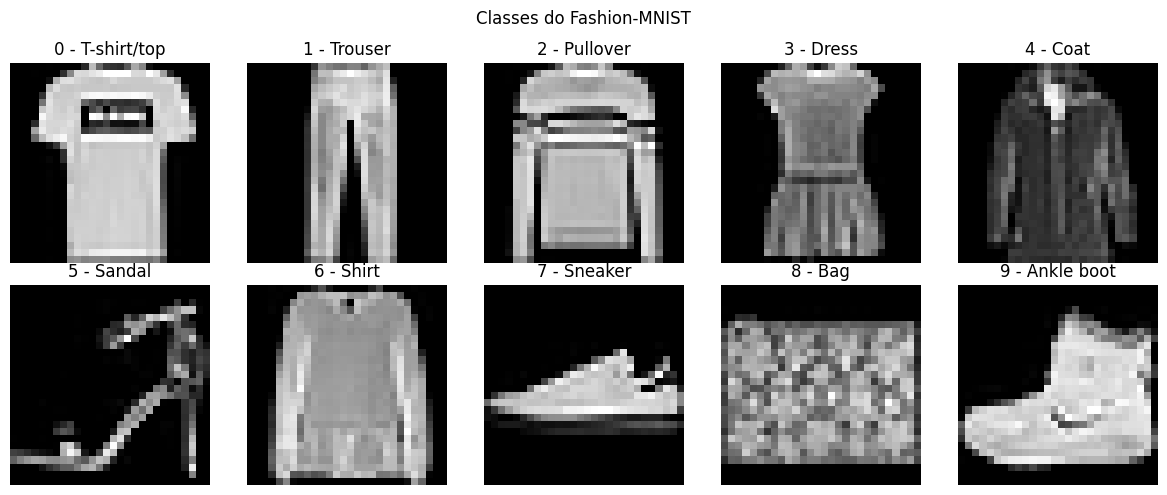

In [5]:
# Definir nomes das classes do Fashion-MNIST

nomes_classes = ["T-shirt/top",    "Trouser",    "Pullover",    "Dress",    "Coat",    "Sandal",    "Shirt",    "Sneaker",    "Bag",    "Ankle boot"]

# Visualizar uma imagem de cada classe do conjunto de dados

plt.figure(figsize=(12, 5))

for classe in range(10):

    # Localizar a primeira imagem pertencente à classe
    indice = np.where(dados["y_train"] == classe)[0][0]

    plt.subplot(2, 5, classe + 1)
    plt.imshow(dados["X_train"][indice], cmap="gray")
    plt.title(f"{classe} - {nomes_classes[classe]}")
    plt.axis("off")

# Configurar o gráfico

plt.suptitle("Classes do Fashion-MNIST")
plt.tight_layout()

plt.show()

## Perguntas

1. Quantas variáveis de entrada e quantas classes existem?  
  Existem 784 variáveis de entrada e 10 classes
2. O que representa cada variável de entrada neste conjunto de dados?  
  Cada variável de entrada representa um pixel da imagem, cada pixel pode ter tons de cinza diferentes
3. Por que um problema com essa quantidade de variáveis e classes pode ser interessante para avaliar diferentes arquiteturas e hiperparâmetros de uma RN?  
  Porque as 784 variávevis de entrada e as 10 classes geram uma boa quantidade de parâmetros para que os efeitos dos hiperparâmetros possam ser observados, mas ainda é pequeno para ser experimentado localmente

# Split dos Dados

In [6]:
# Preparar os dados para treinamento dos modelos

# Recuperar variáveis de entrada e variável alvo
X_train = dados["X_train"]
y_train = dados["y_train"]

X_test = dados["X_test"]
y_test = dados["y_test"]

# Transformar cada imagem 28x28 em um vetor com 784 variáveis de entrada
X_train = X_train.reshape(X_train.shape[0], 28 * 28)
X_test = X_test.reshape(X_test.shape[0], 28 * 28)

# Normalizar os valores dos pixels para o intervalo entre 0 e 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Exibir quantidade de instâncias e variáveis de entrada
print(f"Treinamento: {len(X_train)} instâncias")
print(f"Teste: {len(X_test)} instâncias")
print(f"Variáveis de entrada: {X_train.shape[1]}")

Treinamento: 60000 instâncias
Teste: 10000 instâncias
Variáveis de entrada: 784


# Construção e Treinamento da RN

In [7]:
# Construir modelo de referência

model = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: ReLU
    layers.Dense(10, activation="softmax")      # Saída: Softmax
])

# Configurar processo de treinamento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),   # Otimizador Adam e taxa de aprendizado
    loss="sparse_categorical_crossentropy",                 # Função de perda
    metrics=["accuracy"]                                    # Métrica de avaliação
)

# Exibir arquitetura do modelo

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Perguntas

4. Quantas camadas ocultas possui a rede e quantos neurônios existem nessa camada?  
  Uma camada oculta com 128 neurônios
5. Qual função de ativação foi utilizada na camada oculta? Qual é seu papel?  
  A função de ativação utilizada foi a Relu e seu papel é introduzir não linearidade
6. Por que a camada de saída possui 10 neurônios e utiliza a função Softmax?  
  Possui 10 neurônios porque são 10 classes. A função Softmax faz a distribuição da probabilidade da imagem pertencer a determinada classe, onde a soma das probabilidades é sempre 1
7. Qual função de perda foi escolhida e por que ela é adequada para este problema?  
  A função de perda escolhida foi a sparse_categorical_crossentropy. Ela é adequada para classificação multiclasse com Softmax porque penaliza o modelo conforme a probabilidade atribuída à classe correta diminui, e a variante sparse aceita rótulos inteiros, que é o formato de y_train.
8. Qual otimizador e qual taxa de aprendizado foram definidos?  
  Adam com learning_rate = 0.001
9. O que acontece se alterarmos `shape=(784,)` para outro valor? Por quê?  
  O treinamento quebra com erro de incompatibilidade de dimensão. Porque o shape da entrada define o tamanho da matriz de pesos da primeira camada e precisa corresponder às 784 posições de cada vetor de X_train.
10. Quantos parâmetros treináveis possui a rede? Como esse valor é calculado a partir da quantidade de entradas, neurônios, pesos e biases?  
  101.770 parâmetros, conforme o model.summary(). A regra para uma camada densa é (entradas × neurônios) + neurônios — a primeira parcela são os pesos (uma conexão entre cada entrada e cada neurônio), a segunda são os biases (um por neurônio).


In [8]:
# Treinar modelo de referência

inicio = time.time()

historico = model.fit(
    X_train,
    y_train,
    epochs=20,             # Número de épocas
    batch_size=128,        # Tamanho do lote
    validation_split=0.20, # Utilizar 20% do treinamento para validação
    verbose=1
)

fim = time.time()

# Exibir tempo total de treinamento

print(f"\nTempo de treinamento: {fim - inicio:.2f} segundos")

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8046 - loss: 0.5706 - val_accuracy: 0.8461 - val_loss: 0.4428
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8532 - loss: 0.4186 - val_accuracy: 0.8587 - val_loss: 0.3978
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8665 - loss: 0.3763 - val_accuracy: 0.8677 - val_loss: 0.3744
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8758 - loss: 0.3489 - val_accuracy: 0.8692 - val_loss: 0.3622
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8826 - loss: 0.3284 - val_accuracy: 0.8723 - val_loss: 0.3542
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8872 - loss: 0.3125 - val_accuracy: 0.8733 - val_loss: 0.3471
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8917 - loss: 0.2991 - val_accuracy: 0.8758 - val_loss: 0.3427
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8957 - loss: 0.2877 - val_accuracy: 0.

## Perguntas

11. Qual tamanho de lote (batch size) foi utilizado?  
  128 (batch_size=128). São processadas 128 imagens por vez.
12. Considerando a quantidade de instâncias utilizadas no treinamento, aproximadamente quantas atualizações dos parâmetros ocorrem em cada época?  
  375 atualizações por época. O cálculo: validation_split=0.20 reserva 20% das 60.000 imagens para validação, sobrando 48.000 para o treino de fato. Com lotes de 128: 48.000 ÷ 128 = 375 lotes = 375 atualizações por época.
13. Quantas épocas foram utilizadas e o que uma época representa neste treinamento?  
  20 épocas (epochs=20). Uma época é uma passagem completa por todo o conjunto de treinamento, as 48.000 imagens, percorridas em 375 lotes.
14. Qual é o papel do conjunto de validação utilizado durante o treinamento?  
  O conjunto de validação mede a generalização do modelo ao fim de cada época sem entrar no cálculo do gradiente, permitindo detectar overfitting e ajustar hiperparâmetros sem contaminar o conjunto de teste.
15. Como os valores de loss e accuracy se comportaram ao longo das épocas?  
  No treino, a perda caiu continuamente de 0,5727 para 0,1972 e a acurácia subiu de 0,8038 para 0,9288, enquanto na validação a melhora se concentrou nas 6 primeiras épocas, com a val_loss atingindo o mínimo de 0,3391 na época 13 e subindo até 0,3576 ao final, comportamento clássico de overfitting.

# Avaliação

In [9]:
# Avaliar modelo no conjunto de teste

loss_teste, acuracia_teste = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Exibir resultados da avaliação

print(f"Loss no teste: {loss_teste:.4f}")
print(f"Acurácia no teste: {acuracia_teste:.4f}")

Loss no teste: 0.3611
Acurácia no teste: 0.8770


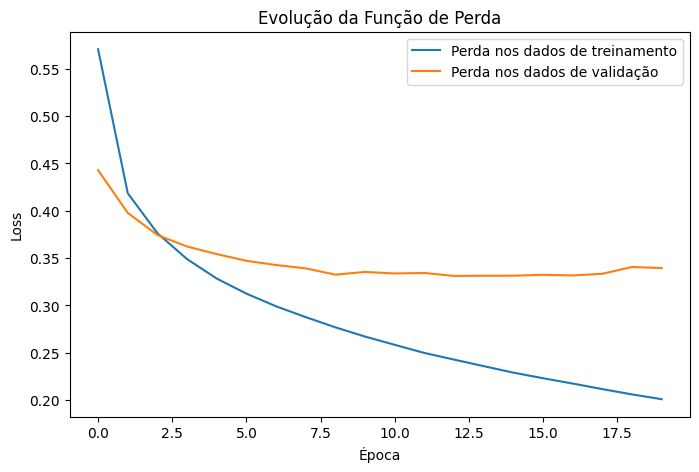

In [10]:
# Visualizar evolução da função de perda durante o treinamento

plt.figure(figsize=(8, 5))

plt.plot(historico.history["loss"], label="Perda nos dados de treinamento")
plt.plot(historico.history["val_loss"], label="Perda nos dados de validação")

# Configurar o gráfico

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da Função de Perda")
plt.legend()

plt.show()

16. O que representam as curvas de perda nos dados de treinamento e de validação?  
  A curva de treino mede o erro nos mesmos dados que o otimizador está usando para ajustar os pesos. Responde: "o quanto o modelo se ajustou ao que ele viu?".  
  A curva de validação mede o mesmo erro em dados que nunca participaram do ajuste. Responde: "o quanto isso vale em dados novos?"
17. Por que a perda nos dados de treinamento continua diminuindo ao longo das épocas?  
  Porque o otimizador minimiza exatamente essa perda, e com 101.770 parâmetros para 48.000 imagens sobra capacidade para a rede memorizar particularidades do conjunto de treino depois que os padrões genéricos já foram aprendidos.
18. A partir de aproximadamente qual época a perda de validação deixa de apresentar melhora significativa?  
  Por volta da época 6, quando a val_loss chega a 0,3426.


In [13]:
# Identificar a época com menor perda de validação

melhor_epoca = np.argmin(historico.history["val_loss"]) + 1
melhor_val_loss = np.min(historico.history["val_loss"])

print(f"Melhor época: {melhor_epoca}")
print(f"Menor val_loss: {melhor_val_loss:.4f}")

Melhor época: 13
Menor val_loss: 0.3312


# Uso do Modelo
Pegue imagens da internet e teste o modelo.

In [14]:
# Carregar e preparar uma nova imagem para classificação

imagem = keras.utils.load_img(
    "bota.png",
    color_mode="grayscale",
    target_size=(28, 28)
)

imagem = keras.utils.img_to_array(imagem)
imagem = imagem / 255.0
imagem = imagem.reshape(1, 784)

# Realizar classificação utilizando o modelo treinado

probabilidades = model.predict(imagem, verbose=0)
classe_prevista = np.argmax(probabilidades)

print(f"Classe prevista: {nomes_classes[classe_prevista]}")
print(f"Probabilidade: {probabilidades[0][classe_prevista] * 100:.2f}%")

Classe prevista: Bag
Probabilidade: 100.00%


## Pergunta
19. Por que o modelo classificou incorretamente a imagem da bota como Bag?  
  Porque a imagem está fora da distribuição de treino — polaridade invertida (fundo branco, objeto escuro), fundo com o xadrez de transparência embutido, objeto descentralizado e ilustração em aquarela em vez de foto de catálogo —, o que faz a rede interpretar o fundo claro como o objeto e apontar Bag

20. Como o modelo pode apresentar probabilidade de 100% e ainda assim estar errado?  
  Porque a Softmax é obrigada a distribuir 100% entre as 10 classes, sem a opção "nenhuma das anteriores", e a cross-entropy treina o modelo para ser assertivo, a probabilidade indica a confiança do modelo, não a probabilidade de ele estar correto.


# Taxa de Aprendizado e Função de Perda

In [15]:
# Construir modelo com nova arquitetura e taxa de aprendizado maior

model_lr = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: 128 neurônios com ReLU
    layers.Dense(64, activation="tanh"),         # 2ª camada oculta: 64 neurônios com Tanh
    layers.Dense(10, activation="softmax")       # Saída: Softmax
])

# Configurar processo de treinamento

model_lr.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),   # Taxa de aprendizado maior
    loss="sparse_categorical_crossentropy",                 # Função de perda
    metrics=["accuracy"]                                    # Métrica de avaliação
)

# Treinar modelo

historico_lr = model_lr.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.20,
    verbose=1
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7971 - loss: 0.5545 - val_accuracy: 0.8358 - val_loss: 0.4586
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8481 - loss: 0.4229 - val_accuracy: 0.8518 - val_loss: 0.4156
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8584 - loss: 0.3931 - val_accuracy: 0.8546 - val_loss: 0.4030
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8636 - loss: 0.3757 - val_accuracy: 0.8609 - val_loss: 0.3885
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8692 - loss: 0.3639 - val_accuracy: 0.8557 - val_loss: 0.4066
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8700 - loss: 0.3567 - val_accuracy: 0.8492 - val_loss: 0.4154
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8735 - loss: 0.3504 - val_accuracy: 0.8638 - val_loss: 0.3806
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8741 - loss: 0.3499 - val_accuracy: 0

## Perguntas
21. Qual hiperparâmetro de treinamento foi alterado em relação ao modelo de referência e qual foi a alteração realizada?  
  A taxa de aprendizado do Adam, que passou de 0,001 para 0,01.
22. Comparando os dois treinamentos, que efeito o aumento da taxa de aprendizado produziu sobre o comportamento da loss e da accuracy?  
  O treinamento ficou instável e pior: a val_loss passou a oscilar de forma errática (0,3715 na época 13 e 0,4216 na 16, sem tendência clara) e a acurácia de treino estagnou em ~0,88 em vez de continuar subindo, terminando com val_accuracy de 0,8665 contra 0,8823 do modelo de referência.
23. Quais hiperparâmetros de arquitetura também foram alterados em relação ao modelo de referência? Identifique as mudanças realizadas na quantidade de camadas ocultas, no número de neurônios e na função de ativação.  
  Foi acrescentada uma segunda camada oculta com 64 neurônios e função de ativação tanh, passando de uma para duas camadas ocultas. A primeira permaneceu com 128 neurônios e ReLU.

# Otimizador

In [ ]:
# Construir modelo com a mesma arquitetura e outro otimizador

model_sgd = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: 128 neurônios com ReLU
    layers.Dense(64, activation="tanh"),        # 2ª camada oculta: 64 neurônios com Tanh
    layers.Dense(10, activation="softmax")      # Saída: Softmax
])

# Configurar processo de treinamento

model_sgd.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),    # Alterar apenas o otimizador
    loss="sparse_categorical_crossentropy",                # Manter função de perda
    metrics=["accuracy"]                                   # Métrica de avaliação
)

# Treinar modelo

historico_sgd = model_sgd.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.20,
    verbose=1
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6571 - loss: 1.1457 - val_accuracy: 0.7470 - val_loss: 0.7867
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7690 - loss: 0.7045 - val_accuracy: 0.7878 - val_loss: 0.6379
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7990 - loss: 0.6021 - val_accuracy: 0.8072 - val_loss: 0.5715
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8133 - loss: 0.5486 - val_accuracy: 0.8179 - val_loss: 0.5327
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8225 - loss: 0.5152 - val_accuracy: 0.8239 - val_loss: 0.5071
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8296 - loss: 0.4919 - val_accuracy: 0.8295 - val_loss: 0.4887
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8345 - loss: 0.4745 - val_accuracy: 0.8337 - val_loss: 0.4745
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8395 - loss: 0.4607 - val_accuracy: 0.

## Perguntas
24. Qual hiperparâmetro foi alterado em relação ao modelo anterior e qual foi a alteração realizada?  
  O otimizador, que passou de Adam para SGD, mantendo a taxa de aprendizado em 0,01.
25. Mantendo a mesma arquitetura, a mesma taxa de aprendizado, a mesma função de perda, o mesmo número de épocas e o mesmo tamanho de lote, que diferenças podem ser observadas no treinamento com Adam e SGD?  
  O SGD aprende bem mais devagar, mas de forma mais estável: sua curva cai de forma contínua e sem altos e baixos, só que depois de 20 épocas chega a apenas 0,7801 de val_accuracy, resultado que o Adam já passava logo na primeira época (0,8469) e bem abaixo dos 0,8665 que o Adam alcançou na mesma arquitetura. A diferença está em como cada um atualiza os pesos: o SGD apenas multiplica o gradiente pela taxa de aprendizado e usa o mesmo passo para todos os parâmetros, enquanto o Adam junta Momentum (aproveita as atualizações anteriores, como uma inércia) e RMSprop (ajusta o tamanho do passo de cada parâmetro conforme o histórico dos gradientes), o que faz ele aprender muito mais rápido, mas com a instabilidade que apareceu na questão 22.
26. Considerando todo o laboratório, explique a diferença entre hiperparâmetros de arquitetura e hiperparâmetros de treinamento, citando exemplos utilizados nos modelos construídos.  
  Os hiperparâmetros de arquitetura definem a estrutura da rede e existem antes do treino, como a quantidade de camadas ocultas, o número de neurônios e a função de ativação (o segundo modelo ganhou uma segunda camada oculta de 64 neurônios com tanh além da de 128 com ReLU), enquanto os hiperparâmetros de treinamento controlam como os pesos dessa estrutura são ajustados, como o otimizador (Adam no primeiro, SGD no último), a taxa de aprendizado (0,001 no modelo de referência e 0,01 nos demais), o tamanho do lote (128) e o número de épocas (20).